# Promoter Panel Selection Pipeline — Annotated Copy

This is an annotated copy of `newsamplingmethod.ipynb` (original left untouched). Markdown notes explain each step, and summary graphs of gene counts through the selection funnel have been appended at the end. No analysis logic was changed.

**Overall pipeline:** all genes with RNA-seq data → compute expression + stability + combined Score → restrict to genes with AlphaFold-confirmed structural annotation (from `genomeAlignment.ipynb`) → select 12 genes evenly spaced across the Score distribution → extract promoter sequences and design primers.

## Step 1 — Load RNA-seq data and compute expression stability scores
Loads normalized (vsd) RNA-seq counts for every gene across 5 experimental conditions (pIND, Rp_R10 +/-, Rp_R20 +/-), averages replicates within each condition, then computes for every gene: `avgExpression` (mean across conditions) and `stabilityIndex` (1 − normalized log2 std-dev across conditions — higher = more stably expressed, a desirable promoter property).

In [1]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
#import seaborn as sns
from matplotlib.patches import Ellipse
import numpy as np
import matplotlib.transforms as transforms
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord
from Bio.Seq import Seq
import matplotlib.colors as mcolors
#from matplotlib_venn import venn3
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
import matplotlib as mpl
import gzip

#Import the normalized RNA-seq data
norm_data = pd.read_csv('2025-05-19_24TG06_vsd_Rp.csv.gz', compression='gzip', header=0)
norm_df = pd.DataFrame(norm_data)

#Identifying the different experimental conditions
pIND = norm_df.columns[1:11]
Rp_R10_pos = norm_df.columns[11:16]
Rp_R10_neg = norm_df.columns[16:21]
Rp_R20_pos = norm_df.columns[21:26]
Rp_R20_neg = norm_df.columns[26:31]

#Averaging the expression levels within experimental conditions
avg_df = norm_df.iloc[:, [0]].set_axis(["index"], axis=1)
avg_df['pIND'] = norm_df[pIND].mean(axis=1)
avg_df['Rp_R10_pos'] = norm_df[Rp_R10_pos].mean(axis=1)
avg_df['Rp_R10_neg'] = norm_df[Rp_R10_neg].mean(axis=1)
avg_df['Rp_R20_pos'] = norm_df[Rp_R20_pos].mean(axis=1)
avg_df['Rp_R20_neg'] = norm_df[Rp_R20_neg].mean(axis=1)

#Averaging across experimental conditions
conditions = avg_df.columns[1:6]
avg_df['avgExpression'] = avg_df[conditions].mean(axis=1)

#Doing a log transformtation of the average values within an experimental condition of the form:
#Log2(x+1)
log_df = avg_df.copy()
log_df.iloc[:, 1:] = np.log2(log_df.iloc[:, 1:] + 1)

#Calculating the population standard deviation across the log transformed experimental conditions
log_df["Variation"] = log_df.iloc[:, 1:6].std(axis=1, ddof=0)

#Creating a stability index of the form:
#1 - (variation/max(variation))
log_df["stabilityIndex"] = 1 - (log_df["Variation"]/log_df["Variation"].max())

#Compiling all the data into one dataframe
final_df = norm_df.iloc[:, [0]].set_axis(["index"], axis=1)
final_df['avgExpression'] = avg_df['avgExpression']
final_df['Variation'] = log_df['Variation']
final_df['stabilityIndex'] = log_df['stabilityIndex']

#Top 100 stable genes (potential top promoters)
top_promoters = final_df.nlargest(100, 'stabilityIndex').iloc[:,:]

## Step 2 — Visualize the expression/stability landscape
Density-colored scatter of every gene's `avgExpression` vs `stabilityIndex`, used to eyeball the distribution before selecting candidate promoters.

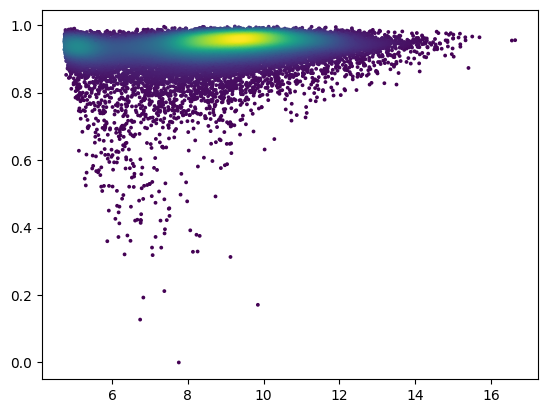

In [2]:
from scipy.stats import gaussian_kde

x = final_df['avgExpression']
y = final_df['stabilityIndex']

xy = np.vstack([x,y])
z = gaussian_kde(xy)(xy)

idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
ax.scatter(x,y,c=z, s=3)
plt.show()

## Step 3 — Quantile-based candidate sampling (exploratory)
Bins all genes into 12 quantiles by `avgExpression` and separately by `stabilityIndex`, sampling one gene per bin each way — early exploratory promoter sets, superseded by the combined-score approach below.

In [3]:
N = 12
final_df["_bin_ae"] = pd.qcut(
    final_df['avgExpression'],
    q=N,
    labels=False
)
promoter_set_exp = (
    final_df
    .groupby("_bin_ae")
    .sample(n=1, random_state=42069)[['index','avgExpression','stabilityIndex']]
    .sort_values('avgExpression')
    .reset_index(drop=True)
)
final_df.drop(columns="_bin_ae", inplace=True)

final_df["_bin_si"] = pd.qcut(
    final_df['stabilityIndex'],
    q=N,
    labels=False
)
promoter_set_si = (
    final_df
    .groupby("_bin_si")
    .sample(n=1, random_state=691738)[['index','avgExpression','stabilityIndex']]
    .sort_values('stabilityIndex')
    .reset_index(drop=True)
)
final_df.drop(columns="_bin_si", inplace=True)

## Step 4 — Combined Score and quantile sampling on Score
Defines `Score = avgExpression × stabilityIndex` to jointly reward highly and stably expressed genes, then samples one gene per Score-quantile (12 bins) as another candidate set.

In [4]:
final_df['Score'] = final_df['avgExpression'] * final_df['stabilityIndex']

final_df["_bin_sc"] = pd.qcut(
    final_df['Score'],
    q=N,
    labels=False
)
promoter_set_score = (
    final_df
    .groupby("_bin_sc")
    .sample(n=1, random_state=6769699)[['index','Score','avgExpression','stabilityIndex']]
    .sort_values('Score')
    .reset_index(drop=True)
)

final_df.drop(columns='_bin_sc', inplace=True)
promoter_set_score.loc[12] = ['g13472', 15.901913517164713, 16.64114148907991, 0.9555782893619236]

I just thought of something. Carlos's stability index score only normalizes across the 12 genes I have selected, but my stability index is normalized against the entire genome.

## Step 6 — Pull protein sequences for a candidate gene set
Extracts protein FASTA sequences for the current candidate gene IDs from the BRAKER proteome, for downstream primer design / sequence checks.

In [5]:
#import braker files to search for protein sequence
input_fasta = "braker.faa.gz"
output_fasta = "promoter_genes_feb20.fa"

# Convert gene IDs to a set of strings for fast lookup
gene_ids = set(promoter_set_score['index'].astype(str))

with gzip.open(input_fasta, "rt") as handle, open(output_fasta, "w") as out:
    for record in SeqIO.parse(handle, "fasta"):
        # Remove .t1 or .t2 suffix from BRAKER IDs
        if record.id.endswith(".t1") and record.id.split(".")[0] in gene_ids:
            SeqIO.write(record, out, "fasta")

print(f"Done! Wrote protein sequences for {len(gene_ids)} genes.")

Done! Wrote protein sequences for 13 genes.


## Step 7 — Pull CDS nucleotide sequences for the candidate genes
Extracts the first-isoform CDS nucleotide sequence per candidate gene from the assembly CDS FASTA.

In [6]:
#import fasta files to search for nucleotide sequence
input_nuc = "assembly_cds.fasta"
output_nuc = "promoter_set_cds_feb20.fasta"

seen_genes = set()

with open(output_nuc, "w") as out_fh:
    for record in SeqIO.parse(input_nuc, "fasta"):
        # parse header fields
        fields = {
            f.split("=")[0]: f.split("=")[1]
            for f in record.id.split(";")
            if "=" in f
        }

        gene = fields.get("Parent")   # gene-level ID (e.g. g1)

        # keep only first isoform per gene
        if gene in gene_ids and gene not in seen_genes:
            SeqIO.write(record, out_fh, "fasta")
            seen_genes.add(gene)


## Step 8 — Extract upstream promoter regions
Using BLAST coordinates of each CDS against the genome assembly, extracts the 1000 bp immediately upstream of each gene (respecting strand) as its candidate promoter sequence.

In [7]:
# Load BLAST results
cols = ["qseqid", "contig", "start", "end", "strand", "pident", "length"]
blast = pd.read_csv("cds_vs_genome.tsv", sep="\t", names=cols)

# Load genome into dictionary
genome = SeqIO.to_dict(SeqIO.parse("assembly.fasta", "fasta"))

PROMOTER_LEN = 1000
records = []

for _, row in blast.iterrows():
    gene = row.qseqid
    contig = row.contig
    start = int(row.start)
    end = int(row.end)
    strand = row.strand

    seq = genome[contig].seq

    if strand == "plus":
        prom_start = max(0, min(start, end) - PROMOTER_LEN - 1)
        prom_end = min(start, end) - 1
        promoter = seq[prom_start:prom_end]

    elif strand == "minus":
        prom_start = max(start, end)
        prom_end = min(len(seq), prom_start + PROMOTER_LEN)
        promoter = seq[prom_start:prom_end].reverse_complement()

    else:
        continue

    records.append(
        SeqIO.SeqRecord(
            promoter,
            id=f"{gene}_promoter",
            description=""
        )
    )

# Write promoter FASTA
SeqIO.write(records, "promoter_set_upstream_feb20.fasta", "fasta")

13

## Step 9 — Map genes to STRING preferred names
Loads a STRING-DB ID mapping and attaches human-readable preferred gene names.

In [8]:
string_mapping = pd.read_csv('string_mapping_feb_20.tsv', sep='\t',header=0)


ATCC11559V2 = {
    "g20183": "1925376",
    "g18882": "1899529",
    "g7124": "1795999",
    "g16051": "1798840",
    "g21791": "1916071",
    "g10325": "1922015",
    "g16856": "1903650",
    "g15486": "1062622",
    "g2522": "1888202",
    "g22818": "1924314",
    "g7144": "1822622",
    "g2780": "1356428",
    "g13472": "1894307"
}

promoter_set_score['ATCC11559_V2'] = promoter_set_score['index'].map(ATCC11559V2)

In [9]:
promoter_set_score.to_excel("promoter_set_score.xlsx", index=False)

In [10]:
final_df.to_excel("final_df.xlsx", index=False)

## Step 10 — Restrict candidates to genes with confirmed structural/functional annotation
Loads `52813_dictionary.csv`, produced by the genome-annotation pipeline (`genomeAlignment.ipynb`): it lists every BRAKER isoform that had a high-confidence (≥95% identity) match to ATCC 52813 **and** an AlphaFold structure with a real (non-"Uncharacterized") description. This is the key filter connecting the annotation pipeline to promoter selection — only genes we can confidently say something about functionally are eligible to become part of the promoter panel.

In [11]:
filtered_map = pd.read_csv('/Users/wilsonporteus/Library/CloudStorage/OneDrive-ImperialCollegeLondon/Research documentation/Code/mmseq2 alignments/52813_dictionary.csv')

## Step 11 — Filter the expression/score table down to annotated genes only
Keeps only rows of `final_df` (the full expression+stability+score table, all genes with RNA-seq data) whose gene ID also appears in the AlphaFold-characterized dictionary from the previous step — producing `af_df`, the *actual* candidate pool for the final panel.

In [12]:
# Filter filtered_map to only rows where 'query' ends in '.t1'
filtered_t1 = filtered_map[filtered_map['query'].str.endswith('.t1')]

# Extract the base id (e.g. 'g1.t1' -> 'g1') to match final_df's 'index' column
filtered_t1_ids = filtered_t1['query'].str.replace(r'\.t1$', '', regex=True)

# Keep only entries in final_df whose 'index' is in that set
af_df = final_df[final_df['index'].isin(filtered_t1_ids)]

## Step 12 — Final promoter panel selection: 12 genes evenly spaced by Score percentile
From the AlphaFold-characterized, expressed gene pool (`af_df`), selects 12 genes whose combined Score values are as close as possible to 12 evenly spaced percentiles (0–100th), guaranteeing broad, even coverage of the expression/stability spectrum among functionally annotated genes. This is the final panel.

In [13]:
# Sort by score just to make this easier to reason about
sorted_df = af_df.sort_values('Score').reset_index(drop=False)
# (reset_index keeps your gene labels in a column called 'index')

# Define 12 evenly spaced percentiles from 0 to 100
percentiles = np.linspace(0, 100, 12)

# Find the actual score value at each percentile
target_scores = np.percentile(af_df['Score'], percentiles)

# For each target score, find the gene whose score is closest to it
selected_idx = []
used = set()

for target in target_scores:
    # closest remaining row by absolute distance to target score
    diffs = (sorted_df['Score'] - target).abs()
    diffs[sorted_df.index.isin(used)] = np.inf  # avoid picking the same gene twice
    idx = diffs.idxmin()
    selected_idx.append(idx)
    used.add(idx)

promoters_af = sorted_df.loc[selected_idx].sort_values('Score').reset_index(drop=True)
promoters_af = promoters_af[['index', 'Score']]

## Step 13 — Attach protein IDs and descriptions to the final panel
Merges the final 12-gene panel with the AlphaFold/UniProt dictionary to attach each gene's matched protein ID and functional description for reporting.

In [14]:
# Create a gene-id column in filtered_map by stripping the transcript suffix
filtered_map = filtered_map.copy()
filtered_map['gene_id'] = filtered_map['query'].str.split('.').str[0]

# Merge on the gene_id <-> index match
promoters_af = promoters_af.merge(
    filtered_map[['gene_id', 'protein_id', 'uniprot_description']],
    left_on='index',
    right_on='gene_id',
    how='left'
)

# Drop the helper column now that the merge is done
promoters_af = promoters_af.drop(columns='gene_id')

## Step 14 — Export final panel protein sequences
Pulls protein FASTA sequences for the final 12-gene promoter panel.

In [15]:
#import braker files to search for protein sequence
input_fasta = "braker.faa.gz"
output_fasta = "promoter_genes_july7.fa"

# Convert gene IDs to a set of strings for fast lookup
gene_ids = set(promoters_af['index'].astype(str))

with gzip.open(input_fasta, "rt") as handle, open(output_fasta, "w") as out:
    for record in SeqIO.parse(handle, "fasta"):
        # Remove .t1 or .t2 suffix from BRAKER IDs
        if record.id.endswith(".t1") and record.id.split(".")[0] in gene_ids:
            SeqIO.write(record, out, "fasta")

print(f"Done! Wrote protein sequences for {len(gene_ids)} genes.")

#import fasta files to search for nucleotide sequence
input_nuc = "assembly_cds.fasta"
output_nuc = "promoter_set_cds_july7.fasta"

seen_genes = set()

with open(output_nuc, "w") as out_fh:
    for record in SeqIO.parse(input_nuc, "fasta"):
        # parse header fields
        fields = {
            f.split("=")[0]: f.split("=")[1]
            for f in record.id.split(";")
            if "=" in f
        }

        gene = fields.get("Parent")   # gene-level ID (e.g. g1)

        # keep only first isoform per gene
        if gene in gene_ids and gene not in seen_genes:
            SeqIO.write(record, out_fh, "fasta")
            seen_genes.add(gene)

Done! Wrote protein sequences for 12 genes.


---
# Summary graphs: gene counts through the promoter-selection funnel

Reuses variables already computed above; no recomputation of the pipeline itself.

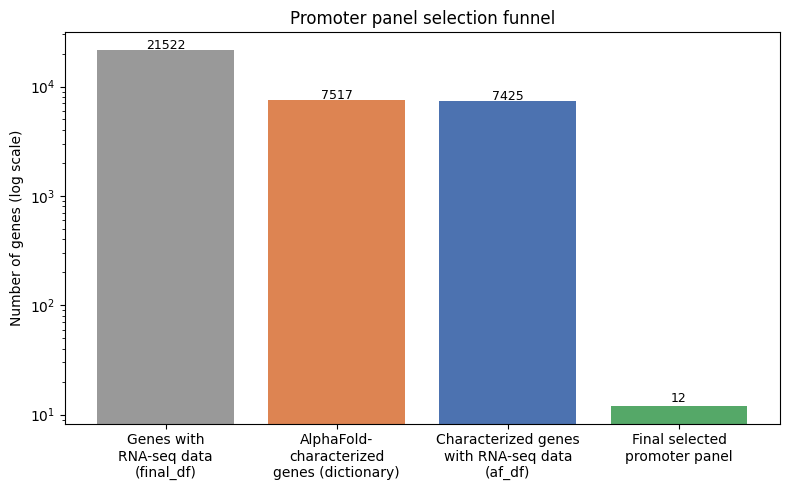

In [16]:
import matplotlib.pyplot as plt

stages = [
    'Genes with\nRNA-seq data\n(final_df)',
    'AlphaFold-\ncharacterized\ngenes (dictionary)',
    'Characterized genes\nwith RNA-seq data\n(af_df)',
    'Final selected\npromoter panel',
]
counts = [len(final_df), filtered_t1_ids.nunique(), len(af_df), len(promoters_af)]

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(stages, counts, color=['#999999', '#DD8452', '#4C72B0', '#55A868'])
for b, v in zip(bars, counts):
    ax.text(b.get_x()+b.get_width()/2, v*1.02 if v>50 else v+1, f'{v}', ha='center', fontsize=9)
ax.set_yscale('log')
ax.set_ylabel('Number of genes (log scale)')
ax.set_title('Promoter panel selection funnel')
plt.tight_layout()
plt.savefig('promoter_selection_funnel.png', dpi=150)
plt.show()

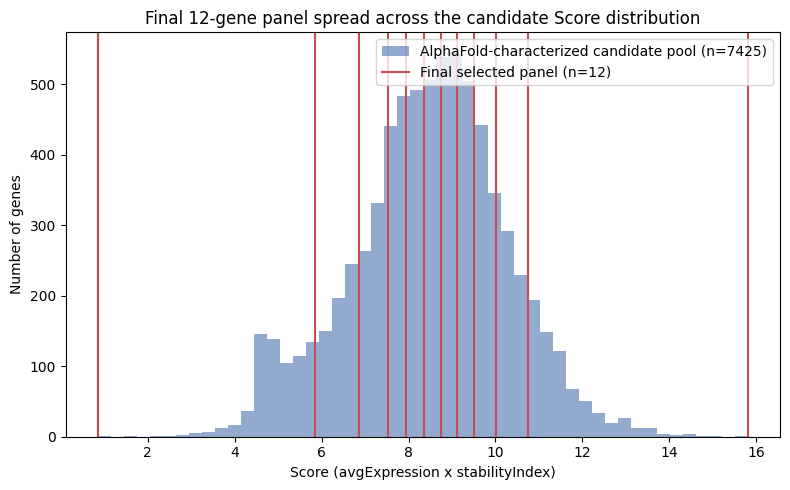

In [17]:
# Where the final 12 selected genes fall along the Score distribution of the eligible candidate pool
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(af_df['Score'], bins=50, color='#4C72B0', alpha=0.6, label=f'AlphaFold-characterized candidate pool (n={len(af_df)})')
for s in promoters_af['Score']:
    ax.axvline(s, color='#C44E52', linewidth=1.5)
ax.axvline(promoters_af['Score'].iloc[0], color='#C44E52', linewidth=1.5, label=f'Final selected panel (n={len(promoters_af)})')
ax.set_xlabel('Score (avgExpression x stabilityIndex)')
ax.set_ylabel('Number of genes')
ax.set_title('Final 12-gene panel spread across the candidate Score distribution')
ax.legend()
plt.tight_layout()
plt.savefig('final_panel_score_distribution.png', dpi=150)
plt.show()